# 10 - Extra Checks

In this notebook I do two extra checks to make the results stronger:

1. **Official forecast:** I compare my models with the official day-ahead forecast for Great Britain from the same data source.
2. **Random seeds:** the deep learning models start from random numbers, so every run is a bit different.
   I train LSTM and PatchTST 5 times with 5 different seeds and look at the average and the spread.

### 1. Import libraries

In [1]:
import os
import time
import logging
import warnings

# if the GPU does not support an operation, run that operation on the CPU
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from neuralforecast import NeuralForecast
from neuralforecast.models import LSTM, PatchTST

warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)

forecast_folder = "../results/forecasts"
tables_folder = "../results/tables"
figures_folder = "../results/figures"

In [2]:
def mae(actual, forecast):
    return np.mean(np.abs(actual - forecast))


def rmse(actual, forecast):
    return np.sqrt(np.mean((actual - forecast) ** 2))


def mape(actual, forecast):
    return np.mean(np.abs(actual - forecast) / actual) * 100


def diebold_mariano(actual, forecast_a, forecast_b):
    d = np.abs(actual - forecast_a) - np.abs(actual - forecast_b)
    dm = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
    p_value = 2 * (1 - stats.norm.cdf(abs(dm)))
    return dm, p_value

In [3]:
# the forecasts of all 5 models from notebook 08 (the filled hours are already removed)
results = pd.read_csv(forecast_folder + "/all_models.csv", parse_dates=["time", "cutoff"])
models = ["Seasonal naive", "SARIMA", "XGBoost", "LSTM", "PatchTST"]
print("Hours used for scoring:", len(results))

Hours used for scoring: 8689


## Part 1: The official forecast

The data file has a column `GB_GBN_load_forecast_entsoe_transparency`. This is the official day-ahead forecast for Great Britain,
published on the ENTSO-E Transparency Platform. It is made **the day before**, so it is a harder task than mine
(my models forecast from midnight, with the data up to midnight).

I saved this column in notebook 01 (`gb_official_forecast_raw.csv`). I never use it as a feature.

In [4]:
official = pd.read_csv("../datasets/raw/gb_official_forecast_raw.csv")
official.columns = ["time", "official"]
official["time"] = pd.to_datetime(official["time"]).dt.tz_localize(None)

clean = pd.read_csv("../datasets/processed/gb_clean_2015_2019.csv")
clean["time"] = pd.to_datetime(clean["time"]).dt.tz_localize(None)

clean = clean.merge(official, on="time", how="left")
clean["error"] = clean["official"] - clean["load"]
clean["year"] = clean["time"].dt.year

ok = (clean["was_filled"] == 0) & clean["official"].notna()
yearly = clean[ok].groupby("year")["error"].agg(["mean", lambda e: e.abs().mean()])
yearly.columns = ["average error (bias)", "MAE"]
yearly.round(0)

,average error (bias),MAE
year,,
2015,-1169.0,1750.0
2016,-1644.0,2053.0
2017,-1548.0,2079.0
2018,-1881.0,2063.0
2019,-2040.0,2312.0


The official forecast is **too low by about 1,000-2,000 MW in every year**. The error is almost always in the same direction.
This is because the official forecast and the actual load column do not measure demand in exactly the same way.

So I show the official forecast in two ways:
- **Official (raw):** the numbers as they are published
- **Official (bias corrected):** I add back the average error for each hour of the day. I learn this average from **2018 only**
  (the validation year), so no information from 2019 is used. This is fair to the official forecast.

In [5]:
# average error for each hour of the day (UTC), learned from 2018 only
in_2018 = ok & (clean["year"] == 2018)
bias_by_hour = clean[in_2018].groupby(clean["time"].dt.hour)["error"].mean()
bias_by_hour.round(0)

time
0    -1835.0
1    -1815.0
2    -1418.0
3    -1275.0
4     -913.0
5     -848.0
6    -1125.0
7    -1836.0
8    -2151.0
9    -2148.0
10   -2054.0
11   -1982.0
12   -1836.0
13   -1719.0
14   -1533.0
15   -1330.0
16   -1395.0
17   -1755.0
18   -2159.0
19   -2529.0
20   -2863.0
21   -3119.0
22   -3101.0
23   -2402.0
Name: error, dtype: float64

In [6]:
results = results.merge(official, on="time", how="left")
results["Official (raw)"] = results["official"]
results["Official (bias corrected)"] = results["official"] - results["time"].dt.hour.map(bias_by_hour).values

# the official forecast is missing for a few hours, so I compare all models on the same hours
same_hours = results[results["official"].notna()].reset_index(drop=True)
print("Hours with an official forecast:", len(same_hours), "of", len(results))

Hours with an official forecast: 8620 of 8689


In [7]:
all_names = models + ["Official (raw)", "Official (bias corrected)"]

rows = []
for name in all_names:
    rows.append([
        name,
        mae(same_hours["actual"], same_hours[name]),
        rmse(same_hours["actual"], same_hours[name]),
        mape(same_hours["actual"], same_hours[name]),
    ])

official_table = pd.DataFrame(rows, columns=["model", "MAE", "RMSE", "MAPE"])
official_table = official_table.sort_values("MAE").reset_index(drop=True)
official_table.to_csv(tables_folder + "/10_official_forecast.csv", index=False)
official_table.round(2)

,model,MAE,RMSE,MAPE
0,XGBoost,1081.48,1413.83,3.30
1,LSTM,1142.37,1487.73,3.55
2,Official (bias corrected),1222.95,1548.40,3.79
3,PatchTST,1250.82,1718.33,3.76
4,SARIMA,1843.29,2527.33,5.48
5,Seasonal naive,1982.04,2695.33,6.10
6,Official (raw),2312.03,2646.98,6.86


Is the best model really better than the official forecast? I use the Diebold-Mariano test again, at 1 hour ahead and 24 hours ahead.

In [8]:
rows = []
for h in [1, 24]:
    one_h = same_hours[same_hours["horizon"] == h]
    for name in models:
        dm, p = diebold_mariano(one_h["actual"].values, one_h[name].values, one_h["Official (bias corrected)"].values)
        if p < 0.05:
            better = name if dm < 0 else "Official (bias corrected)"
        else:
            better = "no significant difference"
        rows.append([h, name, round(dm, 2), round(p, 4), better])

official_dm = pd.DataFrame(rows, columns=["horizon", "model", "DM", "p_value", "better model"])
official_dm.to_csv(tables_folder + "/10_official_dm.csv", index=False)
official_dm

,horizon,model,DM,p_value,better model
0,1,Seasonal naive,6.98,0.0000,Official (bias corrected)
1,1,SARIMA,-13.53,0.0000,SARIMA
2,1,XGBoost,-13.44,0.0000,XGBoost
3,1,LSTM,-1.53,0.1270,no significant difference
4,1,PatchTST,-13.75,0.0000,PatchTST
5,24,Seasonal naive,7.99,0.0000,Official (bias corrected)
6,24,SARIMA,3.42,0.0006,Official (bias corrected)
7,24,XGBoost,-1.41,0.1590,no significant difference
8,24,LSTM,0.29,0.7732,no significant difference
9,24,PatchTST,1.55,0.1207,no significant difference


## Part 2: Training the deep models with 5 seeds

The settings are exactly the same as in notebook 07. Only the random seed changes: 1, 2, 3, 4 and 5.
Each run trains on 2015-2017, stops early using 2018, and forecasts every day of 2019.

In [9]:
data = pd.read_csv("../datasets/processed/gb_features_2015_2019.csv")

df = pd.DataFrame()
df["unique_id"] = ["GB"] * len(data)
df["ds"] = pd.to_datetime(data["time"]).dt.tz_localize(None)
df["y"] = data["load"]

extra_features = ["hour", "day_of_week", "month", "is_weekend", "is_holiday", "temperature"]
for col in extra_features:
    df[col] = data[col]

In [10]:
def run_model(model_name, seed):
    settings = dict(
        h=24,
        input_size=168,
        max_steps=2000,
        val_check_steps=50,
        early_stop_patience_steps=5,
        scaler_type="standard",
        random_seed=seed,
        enable_progress_bar=False,
        enable_model_summary=False,
        logger=False,
    )
    if model_name == "LSTM":
        model = LSTM(futr_exog_list=extra_features, **settings)
    else:
        model = PatchTST(**settings)

    nf = NeuralForecast(models=[model], freq="h")
    cv = nf.cross_validation(df=df, n_windows=365, step_size=24, refit=False, val_size=8760)

    out = pd.DataFrame()
    out["time"] = cv["ds"]
    out["forecast"] = cv[model_name].values
    return out

In [11]:
seeds = [1, 2, 3, 4, 5]
rows = []
seed_forecasts = {}

for model_name in ["LSTM", "PatchTST"]:
    for seed in seeds:
        start = time.time()
        out = run_model(model_name, seed)
        seconds = time.time() - start

        # score on the same hours as notebook 08 (filled hours removed)
        scored = results[["time", "actual", "horizon"]].merge(out, on="time")
        h1 = scored[scored["horizon"] == 1]
        h24 = scored[scored["horizon"] == 24]

        rows.append([
            model_name, seed,
            mae(scored["actual"], scored["forecast"]),
            rmse(scored["actual"], scored["forecast"]),
            mape(scored["actual"], scored["forecast"]),
            mape(h1["actual"], h1["forecast"]),
            mape(h24["actual"], h24["forecast"]),
            seconds,
        ])
        seed_forecasts[model_name + "_" + str(seed)] = scored["forecast"].values
        print(model_name, "seed", seed, "MAE:", round(rows[-1][2]), "MW, time:", round(seconds), "s")

seed_runs = pd.DataFrame(rows, columns=["model", "seed", "MAE", "RMSE", "MAPE", "MAPE_1h", "MAPE_24h", "seconds"])
seed_runs.to_csv(tables_folder + "/10_seed_runs.csv", index=False)
seed_runs.round(2)

Seed set to 1


Seed set to 2


LSTM seed 1 MAE: 1139 MW, time: 155 s


Seed set to 3


LSTM seed 2 MAE: 1161 MW, time: 69 s


Seed set to 4


... (11 outputs left out)

Seed set to 5


PatchTST seed 4 MAE: 1255 MW, time: 356 s


PatchTST seed 5 MAE: 1287 MW, time: 319 s


,model,seed,MAE,RMSE,MAPE,MAPE_1h,MAPE_24h,seconds
0,LSTM,1,1138.61,1483.56,3.54,4.33,4.25,154.96
1,LSTM,2,1161.28,1517.45,3.61,4.34,4.08,68.90
2,LSTM,3,1129.67,1472.34,3.52,4.39,4.13,144.16
3,LSTM,4,1156.70,1515.18,3.61,4.30,4.22,75.63
4,LSTM,5,1148.39,1506.31,3.60,4.50,4.33,46.67
5,PatchTST,1,1246.02,1713.04,3.75,1.96,4.43,358.15
6,PatchTST,2,1237.15,1706.75,3.71,1.83,4.44,371.31
7,PatchTST,3,1231.54,1714.93,3.70,1.76,4.43,357.04
8,PatchTST,4,1255.29,1737.08,3.78,1.95,4.47,356.10
9,PatchTST,5,1287.37,1787.76,3.86,1.74,4.52,319.49


### Average and spread over the 5 seeds

In [12]:
summary = seed_runs.groupby("model")[["MAE", "RMSE", "MAPE", "MAPE_1h", "MAPE_24h"]].agg(["mean", "std", "min", "max"])
summary.round(2)

MAE                              RMSE                           \
             mean    std      min      max     mean    std      min      max   
model                                                                          
LSTM      1146.93  12.95  1129.67  1161.28  1498.97  20.03  1472.34  1517.45   
PatchTST  1251.47  22.00  1231.54  1287.37  1731.91  33.25  1706.75  1787.76   

          MAPE                   MAPE_1h                   MAPE_24h        \
          mean   std   min   max    mean   std   min   max     mean   std   
model                                                                       
LSTM      3.58  0.04  3.52  3.61    4.37  0.08  4.30  4.50     4.20  0.10   
PatchTST  3.76  0.06  3.70  3.86    1.85  0.10  1.74  1.96     4.46  0.04   

                      
           min   max  
model                 
LSTM      4.08  4.33  
PatchTST  4.43  4.52

In [13]:
# a simple table with mean ± standard deviation, next to XGBoost (which gives the same result every time)
rows = []
for model_name in ["LSTM", "PatchTST"]:
    one = seed_runs[seed_runs["model"] == model_name]
    rows.append([model_name, one["MAE"].mean(), one["MAE"].std(), one["MAPE"].mean(), one["MAPE"].std()])
rows.append(["XGBoost", mae(results["actual"], results["XGBoost"]), 0, mape(results["actual"], results["XGBoost"]), 0])

seed_summary = pd.DataFrame(rows, columns=["model", "MAE_mean", "MAE_std", "MAPE_mean", "MAPE_std"])
seed_summary.to_csv(tables_folder + "/10_seed_summary.csv", index=False)
seed_summary.round(2)

,model,MAE_mean,MAE_std,MAPE_mean,MAPE_std
0,LSTM,1146.93,12.95,3.58,0.04
1,PatchTST,1251.47,22.00,3.76,0.06
2,XGBoost,1079.81,0.00,3.29,0.00


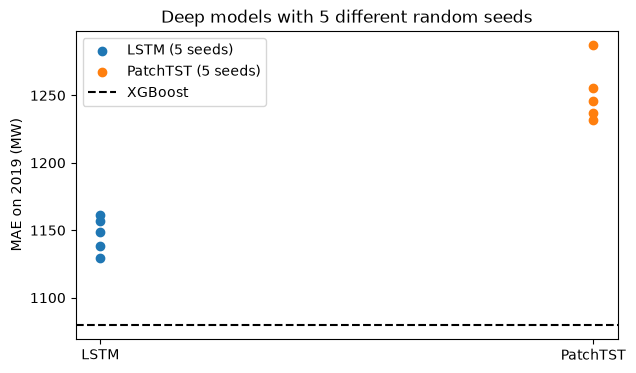

In [14]:
plt.figure(figsize=(7, 4))
for i, model_name in enumerate(["LSTM", "PatchTST"]):
    one = seed_runs[seed_runs["model"] == model_name]
    plt.scatter([i] * len(one), one["MAE"], label=model_name + " (5 seeds)")
xgb_mae = mae(results["actual"], results["XGBoost"])
plt.axhline(xgb_mae, color="black", linestyle="--", label="XGBoost")
plt.xticks([0, 1], ["LSTM", "PatchTST"])
plt.ylabel("MAE on 2019 (MW)")
plt.title("Deep models with 5 different random seeds")
plt.legend()
plt.savefig(figures_folder + "/10_seeds.png")
plt.show()

### Is XGBoost still better than every single run?

I compare XGBoost with each run of LSTM and PatchTST using the Diebold-Mariano test (1 hour ahead and 24 hours ahead).

In [15]:
rows = []
for key, forecast in seed_forecasts.items():
    model_name, seed = key.split("_")
    for h in [1, 24]:
        mask = (results["horizon"] == h).values
        dm, p = diebold_mariano(results["actual"].values[mask], results["XGBoost"].values[mask], forecast[mask])
        if p < 0.05:
            better = "XGBoost" if dm < 0 else model_name
        else:
            better = "no significant difference"
        rows.append([model_name, int(seed), h, round(dm, 2), round(p, 4), better])

seed_dm = pd.DataFrame(rows, columns=["model", "seed", "horizon", "DM", "p_value", "better model"])
seed_dm.to_csv(tables_folder + "/10_seed_dm.csv", index=False)
seed_dm

,model,seed,horizon,DM,p_value,better model
0,LSTM,1,1,-10.74,0.0000,XGBoost
1,LSTM,1,24,-1.60,0.1092,no significant difference
2,LSTM,2,1,-10.70,0.0000,XGBoost
3,LSTM,2,24,-0.72,0.4726,no significant difference
4,LSTM,3,1,-11.27,0.0000,XGBoost
5,LSTM,3,24,-0.97,0.3338,no significant difference
6,LSTM,4,1,-10.47,0.0000,XGBoost
7,LSTM,4,24,-1.55,0.1215,no significant difference
8,LSTM,5,1,-10.90,0.0000,XGBoost
9,LSTM,5,24,-1.96,0.0496,XGBoost


In [16]:
# how many runs does XGBoost win, lose or tie?
pd.crosstab([seed_dm["model"], seed_dm["horizon"]], seed_dm["better model"])

better model      PatchTST  XGBoost  no significant difference
model    horizon                                              
LSTM     1               0        5                          0
         24              0        1                          4
PatchTST 1               3        0                          2
         24              0        5                          0

### Summary

- **Official forecast:** the published official forecast is too low by about 2,000 MW. Even after I correct this with 2018,
  I compare my models with it in the tables above (`10_official_forecast.csv`, `10_official_dm.csv`).
  Remember that the official forecast is made the day before, so it has a harder task.
- **Seeds:** LSTM and PatchTST were trained 5 times each. The tables `10_seed_runs.csv` and `10_seed_summary.csv`
  show how much the results change with the seed, and `10_seed_dm.csv` shows if XGBoost is still better in every run.